# Loss comparison of hazard models (thesis Section: Loss comparison)

- **ELT:** `impact/TC_AUS/TC_AUS_impact_<model>.csv` (event losses and event frequencies).
- **YLT:** `results/annual_losses_v2.csv` (annual aggregate losses; earlier pipeline, CHAZ without frequency correction).
- **Hazard:** `hazard/TC_AUS_windfields/TC_AUS_025res_<model>.hdf5` (cached wind fields, for where damaging winds occur).

Run from the `Honours` folder. Figures are written to `thesis_drafts/figures`.

In [ ]:
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

IMPACT_DIR = Path("impact/TC_AUS")
YLT_PATH = Path("results/annual_losses_v2.csv")
FIG_DIR = Path("thesis_drafts/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)

MODELS = ['IBTrACS', 'STORM', 'CHAZ', 'IRIS']
CF = ['IBTrACS_p', 'WN_MiniTC_repeat', 'WN_MiniTC_perturb']          # quantile-mapped (QM) WN-C sets are not used
ONE_IN = [2, 5, 10, 25, 50, 100, 200, 500, 1000]


## 1. Load event loss tables

In [ ]:
elt = {}
for m in MODELS + CF:
    d = pd.read_csv(IMPACT_DIR / f"TC_AUS_impact_{m}.csv", low_memory=False, dtype={'event_name': str})
    e = d[['event_name', 'event_frequency', 'at_event']].dropna(subset=['event_frequency'])
    elt[m] = e.astype({'event_frequency': float, 'at_event': float}).reset_index(drop=True)
{m: len(e) for m, e in elt.items()}


{'IBTrACS': 3326,
 'STORM': 90607,
 'CHAZ': 269877,
 'IRIS': 53150,
 'IBTrACS_p': 103106,
 'WN_MiniTC_repeat': 33300,
 'WN_MiniTC_perturb': 33300}

## 2. Event losses (ELT)
The *1-in-$T$ year event loss* is the loss exceeded by events at an annual rate of $1/T$: with the events sorted from largest to
smallest, the exceedance rate of the $k$-th largest loss is the sum of the event frequencies of the $k$ largest events. For IBTrACS
(42 years, each event with frequency 1/42) the 1-in-$T$ year event is the $(42/T)$-th largest event, so levels with $T > 42$ are
left blank. The annual rate of loss-causing events and the AAL also use the event frequencies.

In [ ]:
def event_losses(m):
    x = elt[m].at_event.to_numpy()
    return x[x > 0]


def one_in_year_event(m, T):
    # loss whose annual exceedance rate (sum of event frequencies of all events at least as large) first reaches 1/T
    d = elt[m][elt[m].at_event > 0].sort_values('at_event', ascending=False)
    rate = d.event_frequency.cumsum().to_numpy()
    k = np.searchsorted(rate, 1 / T - 1e-12)
    return d.at_event.iloc[k] if rate[0] <= 1 / T + 1e-12 and k < len(d) else np.nan


def elt_stats(m):
    d = elt[m]; L, f = d.at_event.to_numpy(), d.event_frequency.to_numpy()
    r = {'n_loss_events': (L > 0).sum(), 'loss_events_per_yr': f[L > 0].sum(), 'AAL': (L * f).sum()}
    for T in ONE_IN:
        r[f'1in{T}'] = one_in_year_event(m, T)
    r['largest'] = L.max()
    return r


elt_table = pd.DataFrame({m: elt_stats(m) for m in MODELS + CF}).T
money = [c for c in elt_table.columns if c.startswith('1in')] + ['AAL', 'largest']
(elt_table[money] / 1e6).round(2).join(elt_table[['n_loss_events', 'loss_events_per_yr']].round(2))


,1in2,1in5,1in10,1in25,1in50,1in100,1in200,1in500,1in1000,AAL,largest,n_loss_events,loss_events_per_yr
IBTrACS,19.25,65.82,92.70,234.96,NaN,NaN,NaN,NaN,NaN,51.19,597.28,147.0,3.50
STORM,8.47,68.20,199.35,536.43,1058.24,1910.72,3101.34,4874.97,7165.20,108.50,14276.55,9873.0,2.47
CHAZ,11.39,158.44,525.82,1785.72,3866.83,8453.97,17436.43,48220.71,79946.58,563.83,325643.65,19352.0,3.73
IRIS,9.00,124.69,348.77,1120.76,2482.37,4250.83,6266.40,17169.97,29064.70,254.34,54738.90,7218.0,1.80
IBTrACS_p,12.36,79.19,185.81,482.15,1066.19,1668.00,3234.60,4660.06,4895.83,105.99,7472.12,4326.0,3.32
WN_MiniTC_repeat,7.51,49.56,92.70,234.96,491.67,597.28,979.39,2432.99,4297.49,53.52,4405.67,3923.0,3.11
WN_MiniTC_perturb,6.61,61.47,153.31,425.98,754.94,1375.28,1785.98,3782.17,4297.49,79.88,4405.67,3744.0,2.97


In [ ]:
syn = ['STORM', 'CHAZ', 'IRIS']
print('max/min model loss:', {T: round(elt_table.loc[syn, f'1in{T}'].max() / elt_table.loc[syn, f'1in{T}'].min(), 1) for T in [10, 100, 1000]})
cols = ['1in2', '1in5', '1in10', '1in25']
print('ratio to IBTrACS (synthetic models):'); display((elt_table.loc[syn, cols] / elt_table.loc['IBTrACS', cols]).round(2))
print('ratio to IBTrACS (counterfactual sets):'); display((elt_table.loc[CF, cols] / elt_table.loc['IBTrACS', cols]).round(2))
# log-log slope of event loss against T between 1-in-50 and 1-in-500 (loss ~ T^b)
slope = np.log10(elt_table.loc[syn, '1in500'] / elt_table.loc[syn, '1in50'])
pd.DataFrame({'slope_b': slope.round(2), 'tail_index_1_over_b': (1 / slope).round(2)})


max/min model loss: {10: 2.6, 100: 4.4, 1000: 11.2}
ratio to IBTrACS (synthetic models):


,1in2,1in5,1in10,1in25
STORM,0.44,1.04,2.15,2.28
CHAZ,0.59,2.41,5.67,7.60
IRIS,0.47,1.89,3.76,4.77


ratio to IBTrACS (counterfactual sets):


,1in2,1in5,1in10,1in25
IBTrACS_p,0.64,1.20,2.00,2.05
WN_MiniTC_repeat,0.39,0.75,1.00,1.00
WN_MiniTC_perturb,0.34,0.93,1.65,1.81


,slope_b,tail_index_1_over_b
STORM,0.66,1.51
CHAZ,1.10,0.91
IRIS,0.84,1.19


## 3. Annual aggregate losses (YLT)

In [ ]:
ylt = pd.read_csv(YLT_PATH)
YLT_MODELS = ['IBTrACS', 'STORM', 'CHAZ', 'IRIS', 'IBTrACS_p', 'MINI-WNC']


def ylt_stats(m):
    x = ylt.loc[ylt.model == m, 'loss'].to_numpy(); n = len(x)
    r = {'zero_share': (x == 0).mean(), 'mean': x.mean()}
    for T in [2, 5, 10, 25, 100, 200]:
        r[f'1in{T}'] = np.quantile(x, 1 - 1 / T) if T <= n else np.nan
    r['largest'] = x.max(); r['years'] = n
    return r


ylt_table = pd.DataFrame({m: ylt_stats(m) for m in YLT_MODELS}).T
(ylt_table.drop(columns=['zero_share', 'years']) / 1e6).round(0).join(ylt_table[['zero_share', 'years']].round(3))


,mean,1in2,1in5,1in10,1in25,1in100,1in200,largest,zero_share,years
IBTrACS,52.0,9.0,50.0,138.0,286.0,NaN,NaN,601.0,0.000,41.0
STORM,117.0,3.0,66.0,199.0,559.0,2109.0,3373.0,32818.0,0.083,10000.0
CHAZ,650.0,5.0,155.0,560.0,1838.0,11495.0,22969.0,325763.0,0.077,9750.0
IRIS,301.0,4.0,154.0,442.0,1426.0,4789.0,9031.0,57788.0,0.157,10000.0
IBTrACS_p,91.0,7.0,65.0,165.0,457.0,1427.0,2354.0,7901.0,0.001,8000.0
MINI-WNC,69.0,6.0,77.0,159.0,389.0,788.0,1029.0,5050.0,0.010,8000.0


## 4. Exceedance figures

In [ ]:
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
COL = {'IBTrACS': INK, 'STORM': '#7b4fd6', 'CHAZ': '#c99a06', 'IRIS': '#d6337a', 'IBTrACS_p': '#2a78d6',
       'WN_MiniTC_repeat': '#eb6834', 'WN_MiniTC_perturb': '#1baf7a', 'MINI-WNC': '#eb6834'}
LAB = {'IBTrACS': 'IBTrACS (historical)', 'STORM': 'STORM', 'CHAZ': 'CHAZ', 'IRIS': 'IRIS', 'IBTrACS_p': 'IBTrACS_p',
       'WN_MiniTC_repeat': 'WN-C (repeat fill)', 'WN_MiniTC_perturb': 'WN-C (perturbed fill)', 'MINI-WNC': 'WN-C'}
DASHED = {'WN_MiniTC_perturb'}
plt.rcParams.update({'font.size': 10, 'axes.edgecolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
                     'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False})


def one_in(x):
    # sorted losses (descending) and their 1-in-T level, T = (n + 1) / rank
    x = np.sort(x)[::-1]
    return (len(x) + 1) / np.arange(1, len(x) + 1), x


def loglog(ax, xlab, ylab):
    ax.set_xscale('log'); ax.set_yscale('log'); ax.grid(True, color=GRID, lw=0.6); ax.set_axisbelow(True)
    ax.set_xlabel(xlab); ax.set_ylabel(ylab)


def draw(ax, m, T, loss):
    if m == 'IBTrACS':
        ax.plot(T, loss, lw=0, marker='o', ms=4, color=INK, label=LAB[m], zorder=5)
    else:
        ax.plot(T, loss, lw=1.6, color=COL[m], ls='--' if m in DASHED else '-', label=LAB[m])


def one_in_years(m):
    # 1-in-T year event loss: T = 1 / (annual rate of events with loss >= l), from the event frequencies
    d = elt[m][elt[m].at_event > 0].sort_values('at_event', ascending=False)
    return 1 / d.event_frequency.cumsum().to_numpy(), d.at_event.to_numpy()


def elt_panel(ax, models):
    for m in models:
        T, x = one_in_years(m); k = x > 1e5
        draw(ax, m, T[k], x[k])
    loglog(ax, '1-in-$T$ Year', 'Event loss (US$)')
    ax.set_xlim(0.2, 2e4); ax.set_ylim(1e5, 5e11)


def ylt_panel(ax, models):
    for m in models:
        T, x = one_in(ylt.loc[ylt.model == m, 'loss'].to_numpy()); k = x > 0
        draw(ax, m, T[k], x[k])
    loglog(ax, '1-in-$T$ Year', 'Annual aggregate loss (US$)')
    ax.set_xlim(1, 1.2e4); ax.set_ylim(1e6, 5e11)


def save(fig, name):
    fig.tight_layout(); fig.savefig(FIG_DIR / f'{name}.png', dpi=200); plt.show()


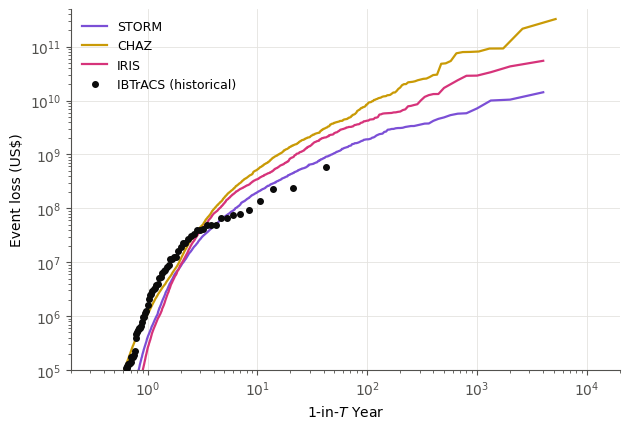

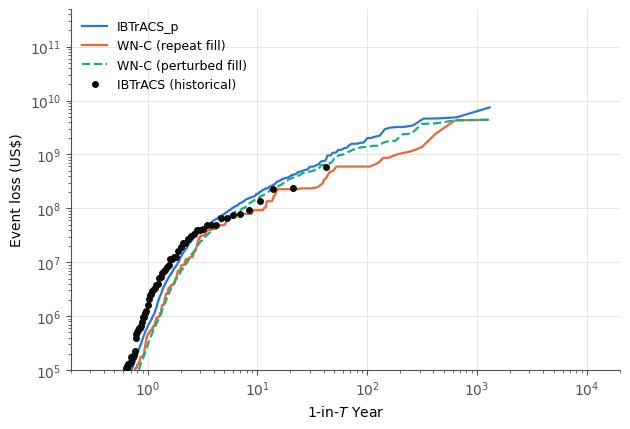

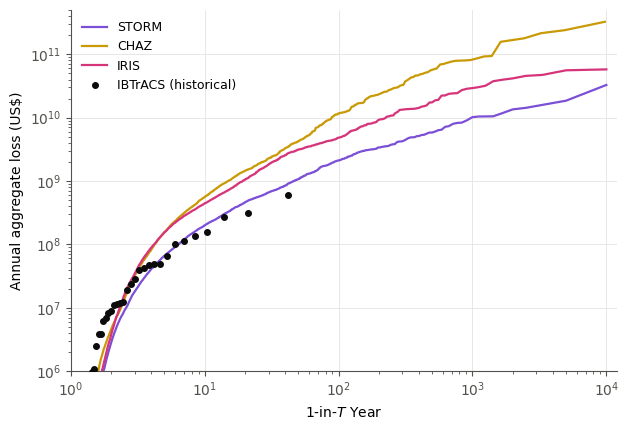

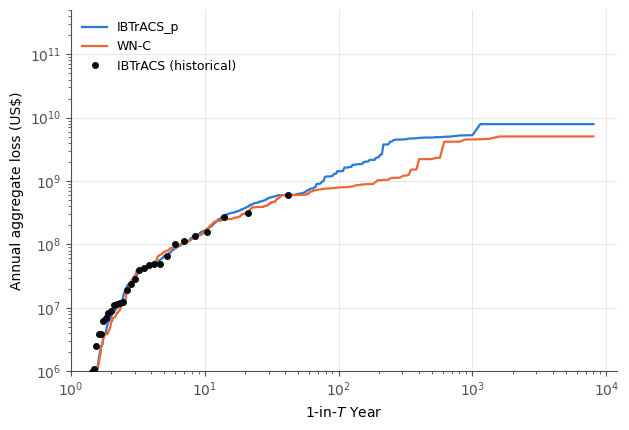

In [ ]:
SYN = ['STORM', 'CHAZ', 'IRIS', 'IBTrACS']


def ep_figure(panel, models, name):
    fig, ax = plt.subplots(figsize=(6.4, 4.4))
    panel(ax, models); ax.legend(loc='upper left', fontsize=9)
    save(fig, name)


# event losses (ELT): synthetic models and counterfactual sets in separate figures
ep_figure(elt_panel, SYN, 'fig_elt_ep_models')
ep_figure(elt_panel, CF + ['IBTrACS'], 'fig_elt_ep_counterfactual')
# annual aggregate losses (YLT)
ep_figure(ylt_panel, SYN, 'fig_ylt_aep_models')
ep_figure(ylt_panel, ['IBTrACS_p', 'MINI-WNC', 'IBTrACS'], 'fig_ylt_aep_counterfactual')


## 5. Spatial distribution of damaging winds
Annual frequency of winds $\geq$ 33 m/s (1-min sustained, ~Category 1) at each grid point, from the cached wind fields
in `hazard/TC_AUS_windfields` and the event frequencies in the impact files.

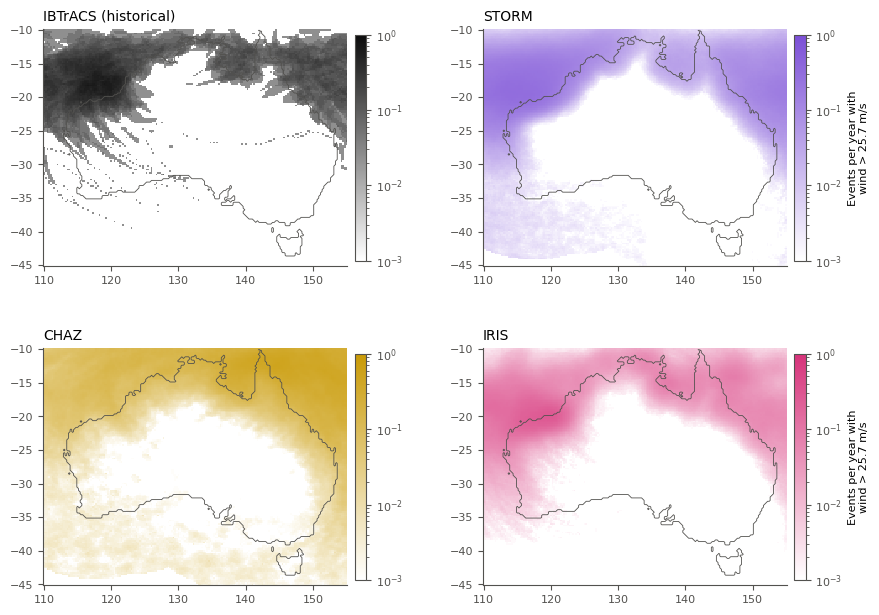

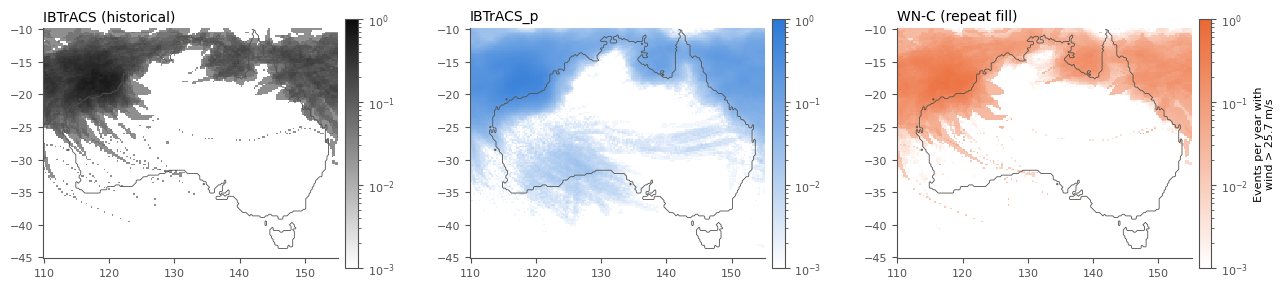

In [ ]:
import h5py, scipy.sparse as sp
from matplotlib.colors import LogNorm, LinearSegmentedColormap

HAZ_DIR = Path("hazard/TC_AUS_windfields")
HAZ_FILES = {'IBTrACS': 'IBTrACS_SH', 'STORM': 'STORM', 'CHAZ': 'CHAZ_SH', 'IRIS': 'IRIS',
             'IBTrACS_p': 'IBTrACS_p_SH', 'WN_MiniTC_repeat': 'WN_MiniTC_repeat'}
# damage onset of the impact function used for the losses: ImpfTropCyclone.from_emanuel_usa() defaults,
# v_thresh = 25.7 m/s, v_half = 74.7 m/s (1-min sustained wind; Emanuel 2011). Below v_thresh the damage ratio is 0,
# so a grid point can only contribute to a loss when its wind exceeds this threshold.
WIND_DAMAGING = 25.7
# centroid grid of every hazard: Centroids.from_pnt_bounds((110, -45, 155, -10), res=0.25), row by row from 10S southwards
NLON, NLAT = 181, 141
GRID_LON, GRID_LAT = 110 + 0.25 * np.arange(NLON), -10 - 0.25 * np.arange(NLAT)

# land outline of Australia from the exposure points
_exp = pd.read_csv(IMPACT_DIR / "TC_AUS_impact_IBTrACS.csv", usecols=['exp_lat', 'exp_lon']).dropna()
_idx = (np.rint((-10 - _exp.exp_lat) / 0.25) * NLON + np.rint((_exp.exp_lon - 110) / 0.25)).astype(int).unique()
LANDMASK = np.zeros(NLON * NLAT); LANDMASK[_idx] = 1; LANDMASK = LANDMASK.reshape(NLAT, NLON)


def wind_frequency(m):
    with h5py.File(HAZ_DIR / f"TC_AUS_025res_{HAZ_FILES[m]}.hdf5", 'r') as f:
        I = sp.csr_matrix((f['intensity/data'][:], f['intensity/indices'][:], f['intensity/indptr'][:]),
                          shape=(f['event_id'].shape[0], NLON * NLAT))
    fr = elt[m].event_frequency.to_numpy()
    assert I.shape[0] == len(fr), f"{m}: hazard and impact event counts differ"
    return np.asarray((I > WIND_DAMAGING).astype(float).T @ fr).ravel().reshape(NLAT, NLON)


wind_freq = {m: wind_frequency(m) for m in HAZ_FILES}
NORM = LogNorm(1e-3, 1)                                   # largest value is 0.69 events/yr (IBTrACS)


def wind_maps(models, name, ncols=2):
    nrows = int(np.ceil(len(models) / ncols))
    fig, axs = plt.subplots(nrows, ncols, figsize=(5.2 * ncols, 3.8 * nrows), squeeze=False)
    for ax in axs.ravel()[len(models):]:
        ax.axis('off')
    for i, (ax, m) in enumerate(zip(axs.ravel(), models)):
        cmap = LinearSegmentedColormap.from_list(m, ['#ffffff', COL[m]])      # white -> the set's colour
        z = np.where(wind_freq[m] > 0, wind_freq[m], np.nan)
        ax.contour(GRID_LON, GRID_LAT, LANDMASK, levels=[0.5], colors=INK2, linewidths=0.6)
        im = ax.pcolormesh(GRID_LON, GRID_LAT, z, norm=NORM, cmap=cmap, shading='auto')
        ax.set_title(LAB[m], fontsize=10, loc='left'); ax.set_aspect('equal'); ax.tick_params(labelsize=8)
        cb = fig.colorbar(im, ax=ax, shrink=0.85, pad=0.02); cb.ax.tick_params(labelsize=8)
        if i % ncols == ncols - 1 or i == len(models) - 1:
            cb.set_label(f'Events per year with\nwind > {WIND_DAMAGING} m/s', fontsize=8)
    fig.savefig(FIG_DIR / f'{name}.png', dpi=200, bbox_inches='tight'); plt.show()


wind_maps(['IBTrACS', 'STORM', 'CHAZ', 'IRIS'], 'fig_map_damaging_wind_models')
wind_maps(['IBTrACS', 'IBTrACS_p', 'WN_MiniTC_repeat'], 'fig_map_damaging_wind_counterfactual', ncols=3)


### Top 5 most damaging events (from the impact files)

In [ ]:
top = pd.concat([elt[m].nlargest(5, 'at_event').assign(model=m, rank=range(1, 6)) for m in MODELS + CF], ignore_index=True)
top.assign(loss_bn=top.at_event / 1e9)[['model', 'rank', 'event_name', 'loss_bn']].round(2)


,model,rank,event_name,loss_bn
0,IBTrACS,1,2015047S15152,0.60
1,IBTrACS,2,1989106S11128,0.23
2,IBTrACS,3,2000105S09127,0.23
3,IBTrACS,4,1999040S15147,0.14
4,IBTrACS,5,1987015S16125,0.09
5,STORM,1,STORM_DATA_IBTRACS_SP_1000_YEARS_0.txt-621-0,14.28
6,STORM,2,STORM_DATA_IBTRACS_SI_1000_YEARS_2.txt-403-14,10.42
7,STORM,3,STORM_DATA_IBTRACS_SP_1000_YEARS_2.txt-409-4,10.03
8,STORM,4,STORM_DATA_IBTRACS_SP_1000_YEARS_2.txt-606-4,7.17
9,STORM,5,STORM_DATA_IBTRACS_SI_1000_YEARS_1.txt-874-5,5.82


## 6. Composition of the WN-C counterfactuals
Fill tracks are named `<SID>_rep<k>` (repeat) or `<SID>_gen<k>` (perturbed); AI members are `<SID>_S<k>`. Raw (not quantile-mapped) WN-C only.

In [ ]:
ib = elt['IBTrACS'].set_index('event_name').at_event
N_HIST_YEARS = 42


def wn_composition(m):
    d = elt[m].copy(); n = d.event_name.astype(str)
    d['sid'] = n.str.split('_').str[0]; d['fill'] = ~n.str.contains(r'_S\d+$')
    ai = d[~d.fill].groupby('sid').at_event
    s = pd.DataFrame({'n_ai': d.groupby('sid').fill.apply(lambda x: (~x).sum())})
    s = s.join(pd.DataFrame({'ai_mean': ai.mean(), 'ai_max': ai.max()}))
    s['hist_loss'] = ib.reindex(s.index).fillna(0).values
    lossy = s[s.hist_loss > 0]; both = lossy[lossy.n_ai > 0]
    return {'fill_share_tracks': d.fill.mean(), 'median_ai_members': s.n_ai.median(), 'storms_no_ai': (s.n_ai == 0).sum(),
            'n_storms': len(s), 'loss_storms': len(lossy), 'loss_storms_no_ai': (lossy.n_ai == 0).sum(),
            'hist_loss_share_no_ai': lossy.hist_loss[lossy.n_ai == 0].sum() / lossy.hist_loss.sum(),
            'median_ai_mean_over_hist': np.median(both.ai_mean / both.hist_loss),
            'share_hist_above_all_ai': (both.hist_loss > both.ai_max).mean(),
            'AAL_ai_only': s.ai_mean.fillna(0)[s.n_ai > 0].sum() / N_HIST_YEARS,
            'AAL_hist_same_storms': s.hist_loss[s.n_ai > 0].sum() / N_HIST_YEARS}


display(pd.Series(wn_composition('WN_MiniTC_repeat'), name='WN_MiniTC_repeat'))
d = elt['WN_MiniTC_repeat']; n = d.event_name.astype(str)
marcia = d[n.str.startswith('2015047S15152') & n.str.contains(r'_S\d+$')]
print('TC Marcia: historical', round(ib['2015047S15152'] / 1e6, 1), '$m; AI members', len(marcia), 'mean', round(marcia.at_event.mean() / 1e6, 1), '$m')
print('Marcia share of total historical loss:', round(ib['2015047S15152'] / ib.sum(), 3))


fill_share_tracks           5.833333e-01
median_ai_members           1.000000e+01
storms_no_ai                2.840000e+02
n_storms                    1.110000e+03
loss_storms                 1.470000e+02
loss_storms_no_ai           3.800000e+01
hist_loss_share_no_ai       2.014531e-01
median_ai_mean_over_hist    1.019736e+00
share_hist_above_all_ai     3.394495e-01
AAL_ai_only                 3.009976e+07
AAL_hist_same_storms        4.087685e+07
Name: WN_MiniTC_repeat, dtype: float64

TC Marcia: historical 597.3 $m; AI members 17 mean 3.5 $m
Marcia share of total historical loss: 0.278


## 7. Counterfactuals as alternative versions of the 42-year record
Every historical storm has $N_{cf}$ = 30 counterfactual versions. Taking the $r$-th version of every storm gives one complete
alternative 1980-2021 record, so the counterfactual sets give 30 alternative 42-year records of annual aggregate loss
(storm year = first 4 digits of the IBTrACS SID). Each record has its own 1-in-$T$ year curve for $T \leq 42$, plotted with
$T = 43/\text{rank}$; the median and 5-95% range across records are compared with the observed record. For IBTrACS_p the
original (unperturbed) track is excluded.

In [ ]:

YEARS = np.arange(1980, 2022); NY = len(YEARS)
T_REC = (NY + 1) / np.arange(1, NY + 1)                     # 1-in-T for rank 1..42
CF_REC = ['IBTrACS_p', 'WN_MiniTC_repeat', 'WN_MiniTC_perturb']


def observed_record():
    d = elt['IBTrACS'].assign(year=lambda x: x.event_name.str[:4].astype(int))
    return np.sort(d.groupby('year').at_event.sum().reindex(YEARS, fill_value=0).to_numpy())[::-1]


def alternative_records(m):
    # rows = realisations r, columns = years; returns each record's annual losses sorted from largest to smallest
    d = elt[m].copy(); n = d.event_name.astype(str)
    d['sid'] = n.str.split('_').str[0]; d['year'] = d.sid.str[:4].astype(int)
    if m == 'IBTrACS_p':
        d = d[n != d.sid]                                    # drop the original track
    d['r'] = d.groupby('sid').cumcount()
    A = d.pivot_table(index='r', columns='year', values='at_event', aggfunc='sum').reindex(columns=YEARS).fillna(0).to_numpy()
    return -np.sort(-A, axis=1)


obs = observed_record()
records = {m: alternative_records(m) for m in CF_REC}
RANKS = {'1-in-2 (median year)': 21, '1-in-5': 8, '1-in-11': 4, '1-in-21': 2, '1-in-43 (largest year)': 1}
rows = []
for label, k in RANKS.items():
    r = {'level': label, 'observed': obs[k - 1] / 1e6}
    for m, S in records.items():
        col = S[:, k - 1]
        r[f'{m} median'] = np.median(col) / 1e6
        r[f'{m} 5%'] = np.quantile(col, .05) / 1e6
        r[f'{m} 95%'] = np.quantile(col, .95) / 1e6
        r[f'{m} share below observed'] = (col < obs[k - 1]).mean()
    rows.append(r)
pd.DataFrame(rows).set_index('level').round(2).T


level,1-in-2 (median year),1-in-5,1-in-11,1-in-21,1-in-43 (largest year)
observed,9.04,65.82,161.09,302.88,601.21
IBTrACS_p median,4.83,84.83,239.23,554.34,1414.32
IBTrACS_p 5%,1.78,48.81,127.55,267.92,437.34
IBTrACS_p 95%,12.51,176.82,492.88,2035.20,4789.73
IBTrACS_p share below observed,0.77,0.23,0.10,0.10,0.10
WN_MiniTC_repeat median,3.82,58.74,158.58,236.32,601.21
WN_MiniTC_repeat 5%,0.45,34.43,76.19,158.58,228.08
WN_MiniTC_repeat 95%,10.34,109.97,290.41,601.21,3458.56
WN_MiniTC_repeat share below observed,0.87,0.53,0.63,0.67,0.67
WN_MiniTC_perturb median,2.67,66.53,184.05,463.59,824.88


In [ ]:
records.items()


dict_items([('IBTrACS_p', array([[4.89582816e+09, 7.05078490e+08, 5.16518463e+08, ...,
        4.04666626e+03, 3.86671341e+03, 4.78331267e+01],
       [3.15943987e+09, 7.10773670e+08, 2.83627729e+08, ...,
        4.99644483e+01, 1.78574565e+01, 7.63697639e-01],
       [3.14291782e+08, 2.00719262e+08, 1.26832183e+08, ...,
        9.93199477e+02, 1.52293413e+01, 4.78252317e+00],
       ...,
       [1.07657301e+09, 7.83945418e+08, 1.96417586e+08, ...,
        6.34733275e+02, 1.34947322e+01, 4.64994837e+00],
       [1.58100796e+09, 8.66120532e+08, 3.91259411e+08, ...,
        1.11103557e+02, 1.02006559e+01, 2.72318857e+00],
       [1.49065554e+09, 4.68348506e+08, 4.50417775e+08, ...,
        1.16652772e+02, 4.86573648e+01, 4.15955983e+01]])), ('WN_MiniTC_repeat', array([[2.49766380e+08, 2.37584136e+08, 7.62916402e+07, ...,
        0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
       [1.37527711e+09, 2.28073569e+08, 1.10262141e+08, ...,
        3.85987618e+01, 0.00000000e+00, 0.00000000e

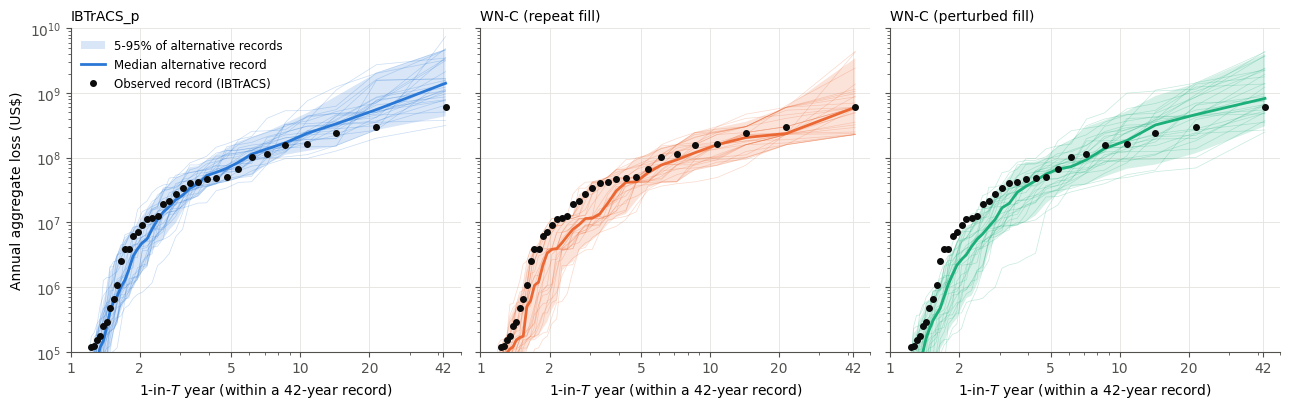

In [ ]:

CC = {'IBTrACS_p': '#2a78d6', 'WN_MiniTC_repeat': '#eb6834', 'WN_MiniTC_perturb': '#1baf7a'}
pos = lambda x: np.where(x > 0, x, np.nan)
fig, axs = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
for ax, m in zip(axs, CF_REC):
    S = records[m]
    for rec in S:
        ax.plot(T_REC, pos(rec), color=CC[m], lw=0.5, alpha=0.25)
    ax.fill_between(T_REC, pos(np.quantile(S, .05, axis=0)), pos(np.quantile(S, .95, axis=0)), color=CC[m], alpha=0.18, lw=0,
                    label='5-95% of alternative records')
    ax.plot(T_REC, pos(np.median(S, axis=0)), color=CC[m], lw=2, label='Median alternative record')
    ax.plot(T_REC, pos(obs), 'o', color=INK, ms=4, label='Observed record (IBTrACS)', zorder=5)
    loglog(ax, '1-in-$T$ year (within a 42-year record)', '')
    ax.set_xlim(1, 50); ax.set_ylim(1e5, 1e10); ax.set_title(LAB[m], loc='left', fontsize=10)
    ax.set_xticks([1, 2, 5, 10, 20, 42]); ax.set_xticklabels(['1', '2', '5', '10', '20', '42'])
axs[0].set_ylabel('Annual aggregate loss (US$)'); axs[0].legend(loc='upper left', fontsize=8.5)
fig.tight_layout(); fig.savefig(FIG_DIR / 'fig_cf_alternative_records.png', dpi=200); plt.show()


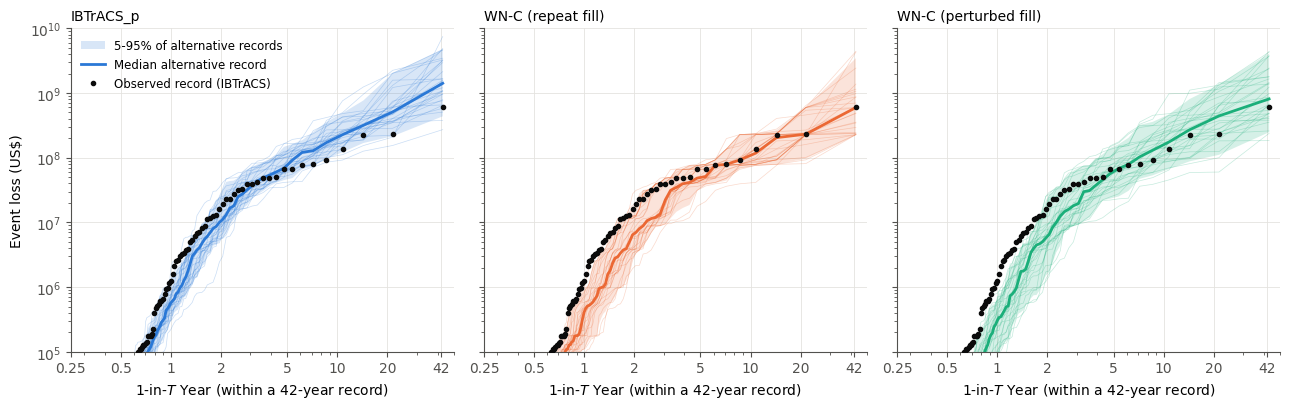

level,1-in-43 (largest event),1-in-21,1-in-11,1-in-5,1-in-2,1-in-1
observed,597.28,234.96,136.13,65.82,16.33,1.26
IBTrACS_p median,1414.32,509.61,226.92,68.75,10.01,0.57
IBTrACS_p 5%,436.19,214.22,121.48,45.05,5.11,0.30
IBTrACS_p 95%,4789.73,2021.07,489.98,146.87,24.65,1.29
WN_MiniTC_repeat median,597.28,230.96,117.61,48.32,6.42,0.41
WN_MiniTC_repeat 5%,227.13,96.37,76.05,31.26,2.69,0.11
WN_MiniTC_repeat 95%,3458.47,597.28,234.96,76.05,17.16,0.91
WN_MiniTC_perturb median,810.29,442.19,174.70,57.06,5.73,0.30
WN_MiniTC_perturb 5%,247.64,110.89,66.74,23.34,1.50,0.07
WN_MiniTC_perturb 95%,4065.60,1351.35,467.82,141.91,21.53,0.67


In [ ]:
# ---- 8. Alternative 42-year records: event losses (1-in-T year) ----
# Within one 42-year record, the k-th largest event loss is exceeded k times in 42 years: T = 43 / k (as for the annual losses)
K_EV = 4 * (NY + 1)                                       # ranks down to T = 0.25 years (about 4 events per year)
T_EV = (NY + 1) / np.arange(1, K_EV + 1)


def top_events(x):
    x = np.sort(np.asarray(x, float))[::-1][:K_EV]
    return np.pad(x, (0, K_EV - len(x)))


def alternative_event_records(m):
    # rows = realisations r; each row = that record's event losses (one version of every storm), largest first
    d = elt[m].copy(); n = d.event_name.astype(str)
    d['sid'] = n.str.split('_').str[0]
    if m == 'IBTrACS_p':
        d = d[n != d.sid]                                    # drop the original track
    d['r'] = d.groupby('sid').cumcount()
    return np.array([top_events(g.at_event) for _, g in d.groupby('r')])


obs_ev = top_events(elt['IBTrACS'].at_event)
ev_records = {m: alternative_event_records(m) for m in CF_REC}

fig, axs = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
for ax, m in zip(axs, CF_REC):
    S = ev_records[m]
    for rec in S:
        ax.plot(T_EV, pos(rec), color=CC[m], lw=0.5, alpha=0.25)
    ax.fill_between(T_EV, pos(np.quantile(S, .05, axis=0)), pos(np.quantile(S, .95, axis=0)), color=CC[m], alpha=0.18, lw=0,
                    label='5-95% of alternative records')
    ax.plot(T_EV, pos(np.median(S, axis=0)), color=CC[m], lw=2, label='Median alternative record')
    ax.plot(T_EV, pos(obs_ev), 'o', color=INK, ms=3, label='Observed record (IBTrACS)', zorder=5)
    loglog(ax, '1-in-$T$ Year (within a 42-year record)', '')
    ax.set_xlim(0.25, 50); ax.set_ylim(1e5, 1e10); ax.set_title(LAB[m], loc='left', fontsize=10)
    ax.set_xticks([0.25, 0.5, 1, 2, 5, 10, 20, 42]); ax.set_xticklabels(['0.25', '0.5', '1', '2', '5', '10', '20', '42'])
axs[0].set_ylabel('Event loss (US$)'); axs[0].legend(loc='upper left', fontsize=8.5)
fig.tight_layout(); fig.savefig(FIG_DIR / 'fig_cf_alternative_records_event.png', dpi=200); plt.show()

RANKS_EV = {'1-in-43 (largest event)': 1, '1-in-21': 2, '1-in-11': 4, '1-in-5': 9, '1-in-2': 22, '1-in-1': 43}
rows = []
for label, k in RANKS_EV.items():
    r = {'level': label, 'observed': obs_ev[k - 1] / 1e6}
    for m, S in ev_records.items():
        col = S[:, k - 1]
        r[f'{m} median'], r[f'{m} 5%'], r[f'{m} 95%'] = np.median(col) / 1e6, np.quantile(col, .05) / 1e6, np.quantile(col, .95) / 1e6
    rows.append(r)
pd.DataFrame(rows).set_index('level').round(2).T
